In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
df = sns.load_dataset("taxis")

print(df.head())

print(df.shape)

               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      

In [4]:
# missing values
print(df.isnull().sum())

# columns containing missing values
print(df.columns[df.isnull().any()])

# Filling missing numerical values with the median
numerical_columns = df.select_dtypes(include="number").columns

for column in numerical_columns:
    df[column] = df[column].fillna(df[column].median())

# Filling missing categorical values with the mode
# Select categorical columns
categorical_columns = df.select_dtypes(
    include=["object", "category", "str"]
).columns

# Fill missing values with the mode
for column in categorical_columns:
    if df[column].isnull().any():
        mode_values = df[column].mode()

        if not mode_values.empty:
            df[column] = df[column].fillna(mode_values.iloc[0])

# Check missing values again
print(df.isnull().sum())

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64
Index([], dtype='str')
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


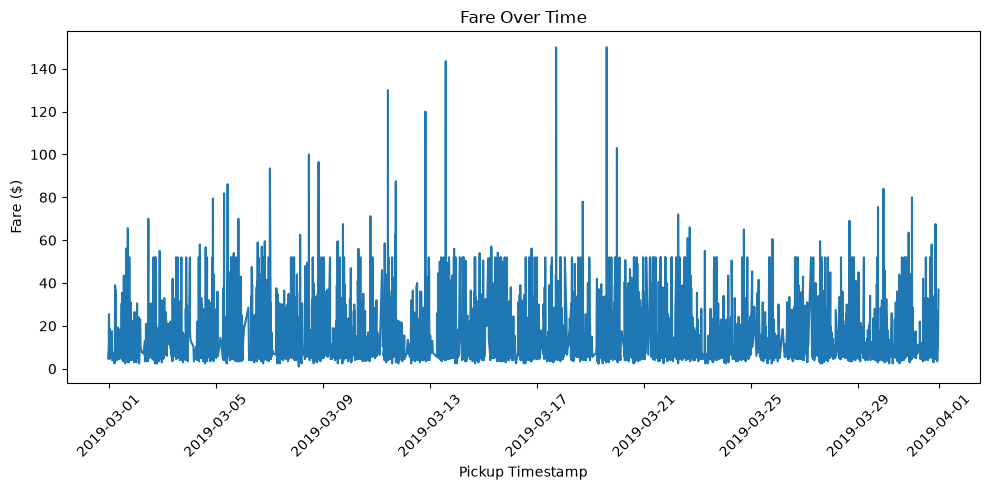

In [5]:
# Converting pickup column to datetime
df["pickup"] = pd.to_datetime(df["pickup"])

# Sorting data by pickup time
df = df.sort_values("pickup")

# line chart
plt.figure(figsize=(10, 5))
plt.plot(df["pickup"], df["fare"])

# title and labels
plt.title("Fare Over Time")
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare ($)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

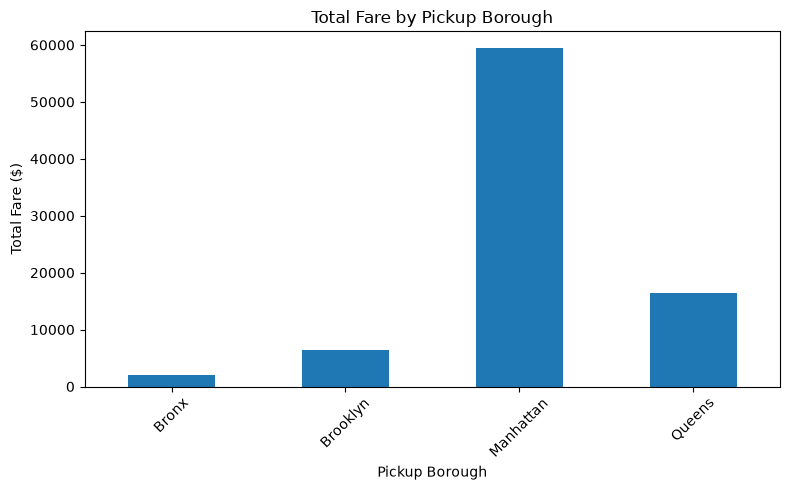

In [6]:
# Total fare for each pickup borough
borough_fare = df.groupby("pickup_borough")["fare"].sum()

# Bar chart
borough_fare.plot(kind="bar", figsize=(8, 5))

# Title and labels
plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare ($)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

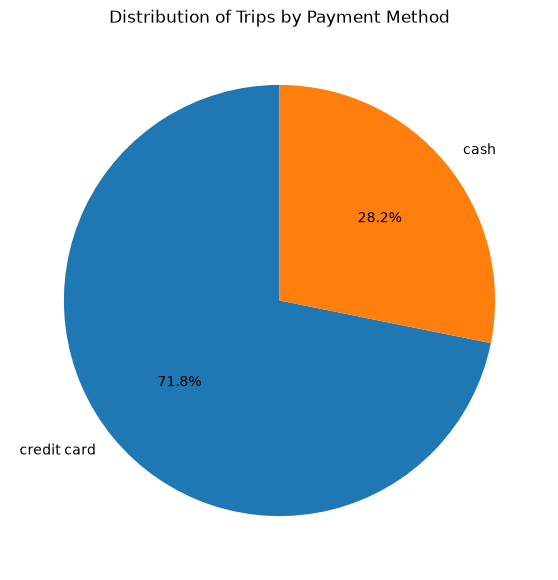

In [7]:
# Counting trips for each payment method
payment_counts = df["payment"].value_counts()

# Pie chart
plt.figure(figsize=(7, 7))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Trips by Payment Method")
plt.show()

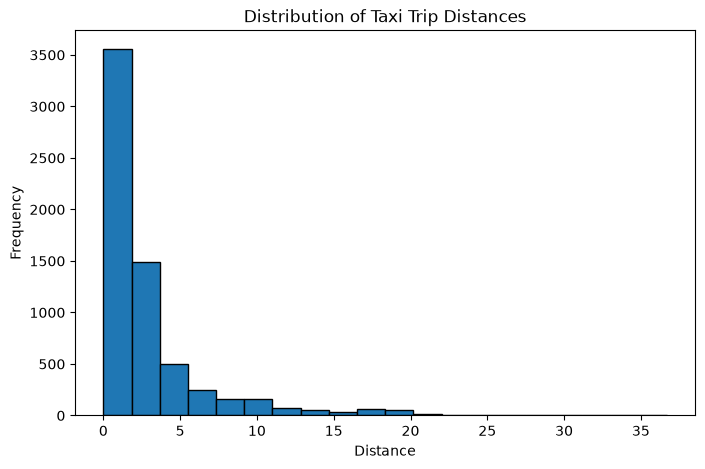

In [8]:
# Histogram to visualize trip distances
plt.figure(figsize=(8, 5))

plt.hist(
    df["distance"].dropna(),
    bins=20,
    edgecolor="black"
)

# Title and labels
plt.title("Distribution of Taxi Trip Distances")
plt.xlabel("Distance")
plt.ylabel("Frequency")

plt.show()

<Figure size 900x500 with 0 Axes>

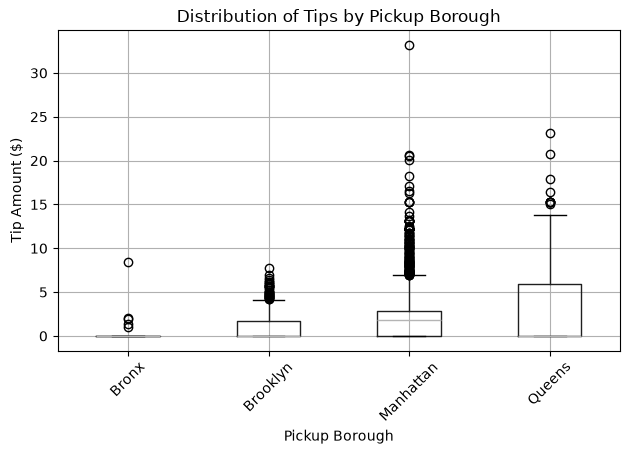

In [9]:
# Creating a box plot of tips by pickup borough
plt.figure(figsize=(9, 5))

df.boxplot(
    column="tip",
    by="pickup_borough"
)

# Title and labels
plt.title("Distribution of Tips by Pickup Borough")
plt.suptitle("")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount ($)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

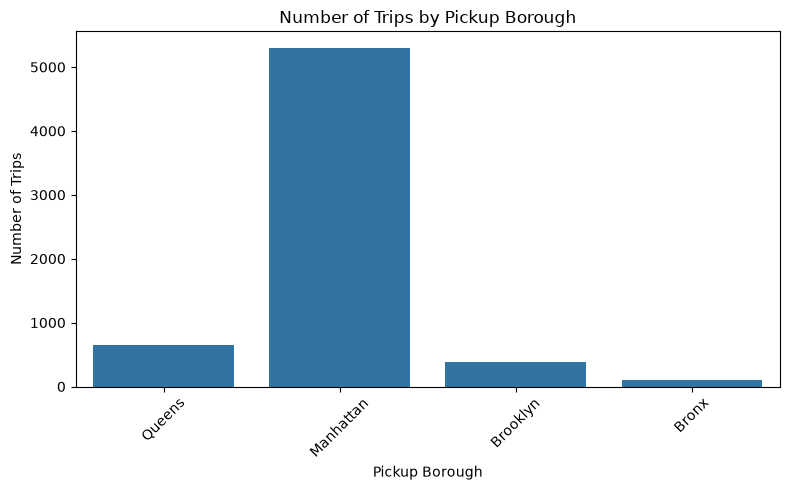

In [10]:
# Count plot
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="pickup_borough")

# Title and labels
plt.title("Number of Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

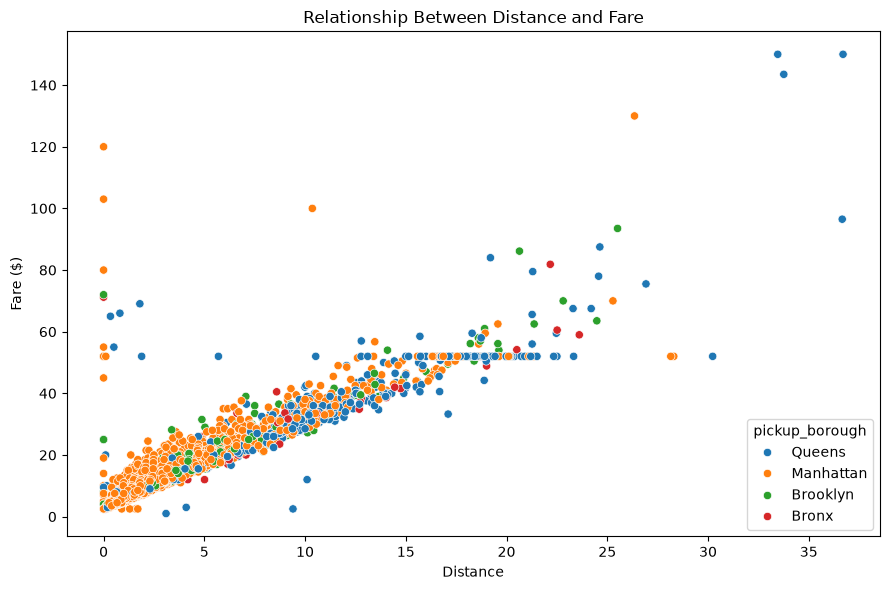

In [11]:
# Scatter plot
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="distance",
    y="fare",
    hue="pickup_borough"
)

# Title and labels
plt.title("Relationship Between Distance and Fare")
plt.xlabel("Distance")
plt.ylabel("Fare ($)")

plt.tight_layout()
plt.show()

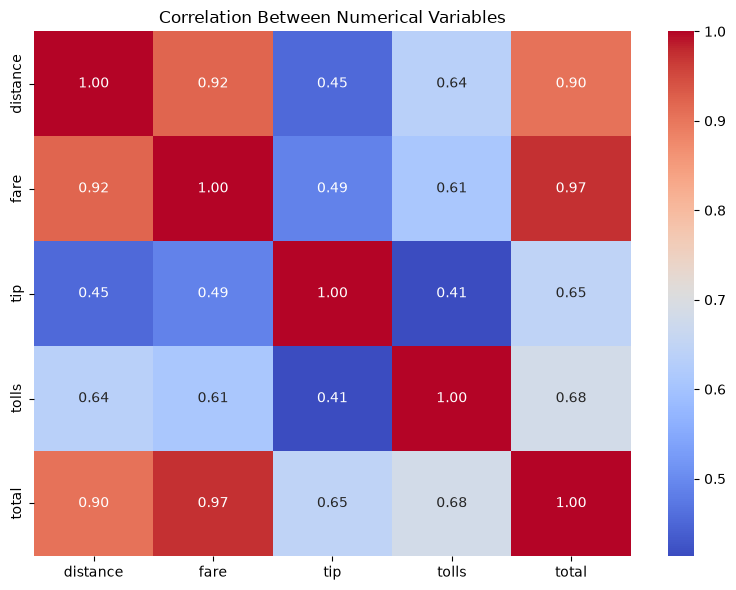

In [12]:
# Numerical columns
numerical_data = df[["distance", "fare", "tip", "tolls", "total"]]

# Calculating the correlation matrix
correlation_matrix = numerical_data.corr()

# Heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

# Title
plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()

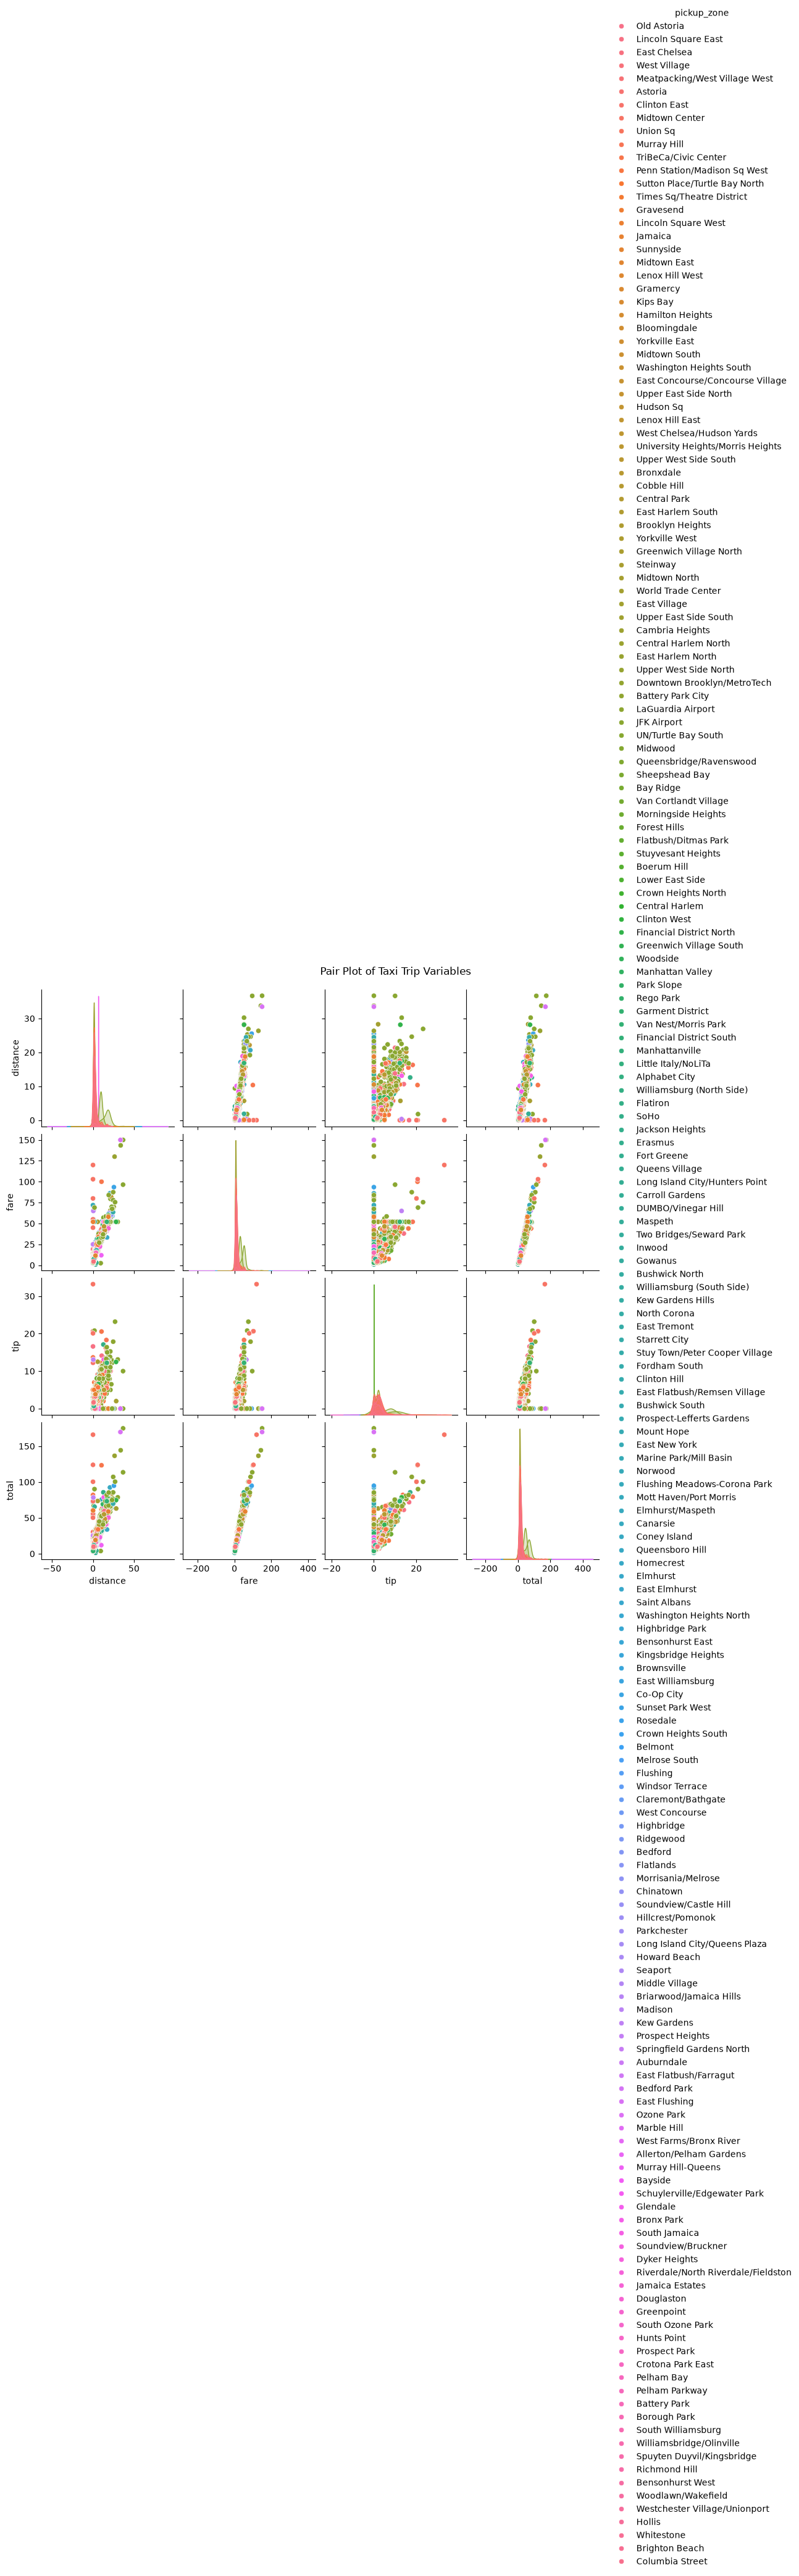

In [14]:
sns.pairplot(
    data=df,
    vars=['distance', 'fare', 'tip', 'total'],
    hue='pickup_zone'
)

plt.suptitle(
    'Pair Plot of Taxi Trip Variables',
    y=1.02
)

plt.show()

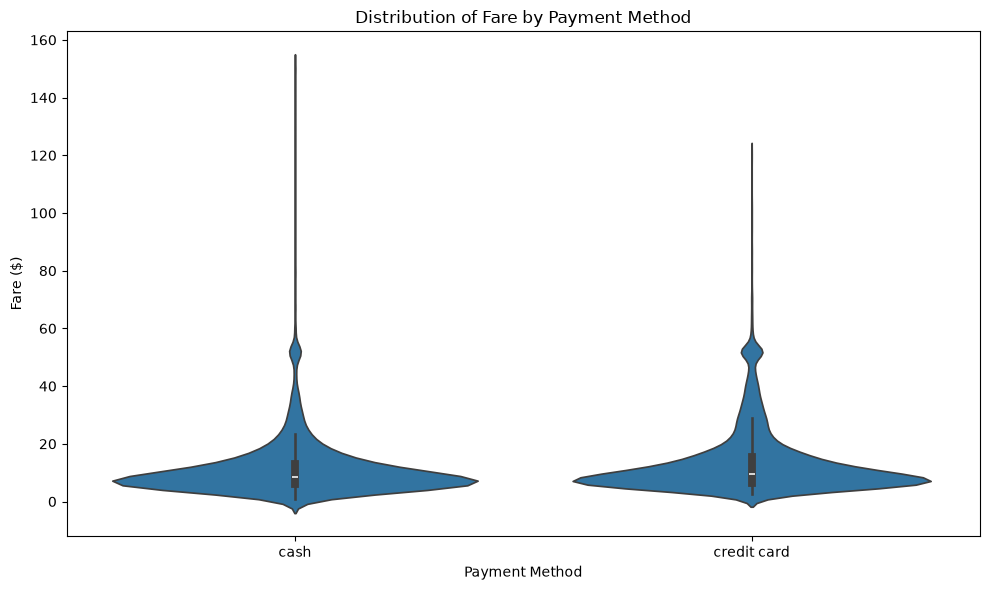

In [15]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x='payment',
    y='fare'
)

plt.title('Distribution of Fare by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare ($)')

plt.tight_layout()
plt.show()